# Exploratory Data Analysis — Relationship Compatibility & Longevity

This notebook explores the synthetic couples dataset used by the pipeline: raw distributions, data quality, target balance and how the engineered pairwise features relate to the targets.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from relcompat.config import load_config
from relcompat.data.generate import generate_couples
from relcompat.data.validate import validate
from relcompat.features.build_features import NUMERIC_FEATURES, build_features

sns.set_theme(style='whitegrid')
cfg = load_config()

## 1. Load data
Uses the raw CSV written by `run_pipeline.py` when it exists, otherwise regenerates it with the configured seed.

In [2]:
raw = pd.read_csv(cfg.raw_path) if cfg.raw_path.exists() else generate_couples(cfg.n_samples, cfg.seed)
print(raw.shape)
raw.head()

(10000, 47)


,p1_age,p2_age,p1_gender,p1_education,p1_income_bracket,p1_religion,p1_religiosity,p1_wants_children,p1_openness,p1_conscientiousness,...,p2_political_leaning,p2_smoker,p2_drinking,distance_km,how_met,months_dating,cohabiting,compatible,longevity_years,lasts_5_years
0,34,28,female,phd,1.0,buddhist,5,unsure,4.5,6.6,...,1,True,social,2.5,other,27.0,True,0,6.53,1
1,24,29,female,bachelors,4.0,jewish,2,yes,4.9,4.4,...,3,False,never,7.7,work,21.0,False,0,1.75,0
2,38,43,male,masters,2.0,hindu,4,yes,9.4,7.4,...,6,False,social,7.3,online,20.0,False,0,11.31,1
3,40,48,female,high_school,3.0,none,4,no,5.6,4.9,...,4,False,social,7.9,online,23.0,False,1,8.22,1
4,18,22,male,high_school,2.0,hindu,3,no,4.5,4.9,...,4,False,social,2.3,online,16.0,True,1,3.09,0


## 2. Data quality
Missing values were injected on purpose (~3% in selected columns) along with a few extreme distances.

In [3]:
missing = raw.isna().mean().mul(100).sort_values(ascending=False)
missing[missing > 0].round(2).to_frame('% missing')

,% missing
p1_openness,3.32
p1_neuroticism,3.27
p2_income_bracket,3.19
p1_communication_score,3.12
p2_communication_score,3.07
p2_neuroticism,3.04
p1_extraversion,3.03
p1_income_bracket,3.02
p2_conscientiousness,3.01
months_dating,3.01


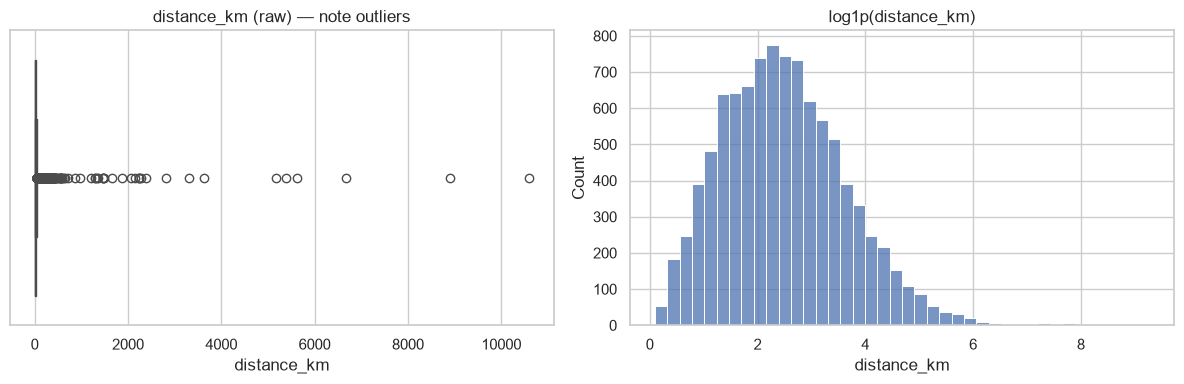

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=raw['distance_km'], ax=axes[0]).set(title='distance_km (raw) — note outliers')
sns.histplot(np.log1p(raw['distance_km'].dropna()), ax=axes[1], bins=40).set(title='log1p(distance_km)')
plt.tight_layout()

In [5]:
clean = validate(raw)
print(f'{len(raw) - len(clean)} rows dropped by validation')

0 rows dropped by validation


## 3. Targets

compatible       0.490
lasts_5_years    0.548
dtype: float64

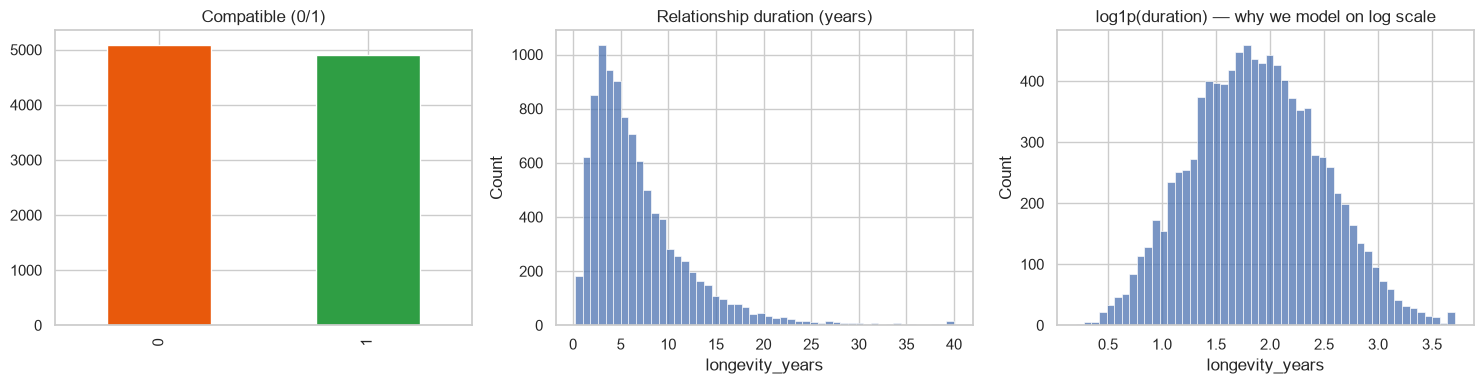

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
clean['compatible'].value_counts().sort_index().plot.bar(ax=axes[0], color=['#e8590c', '#2f9e44'])
axes[0].set(title='Compatible (0/1)', xlabel='')
sns.histplot(clean['longevity_years'], bins=50, ax=axes[1]).set(title='Relationship duration (years)')
sns.histplot(np.log1p(clean['longevity_years']), bins=50, ax=axes[2]).set(title='log1p(duration) — why we model on log scale')
plt.tight_layout()
clean[['compatible', 'lasts_5_years']].mean().round(3)

## 4. Partner attributes

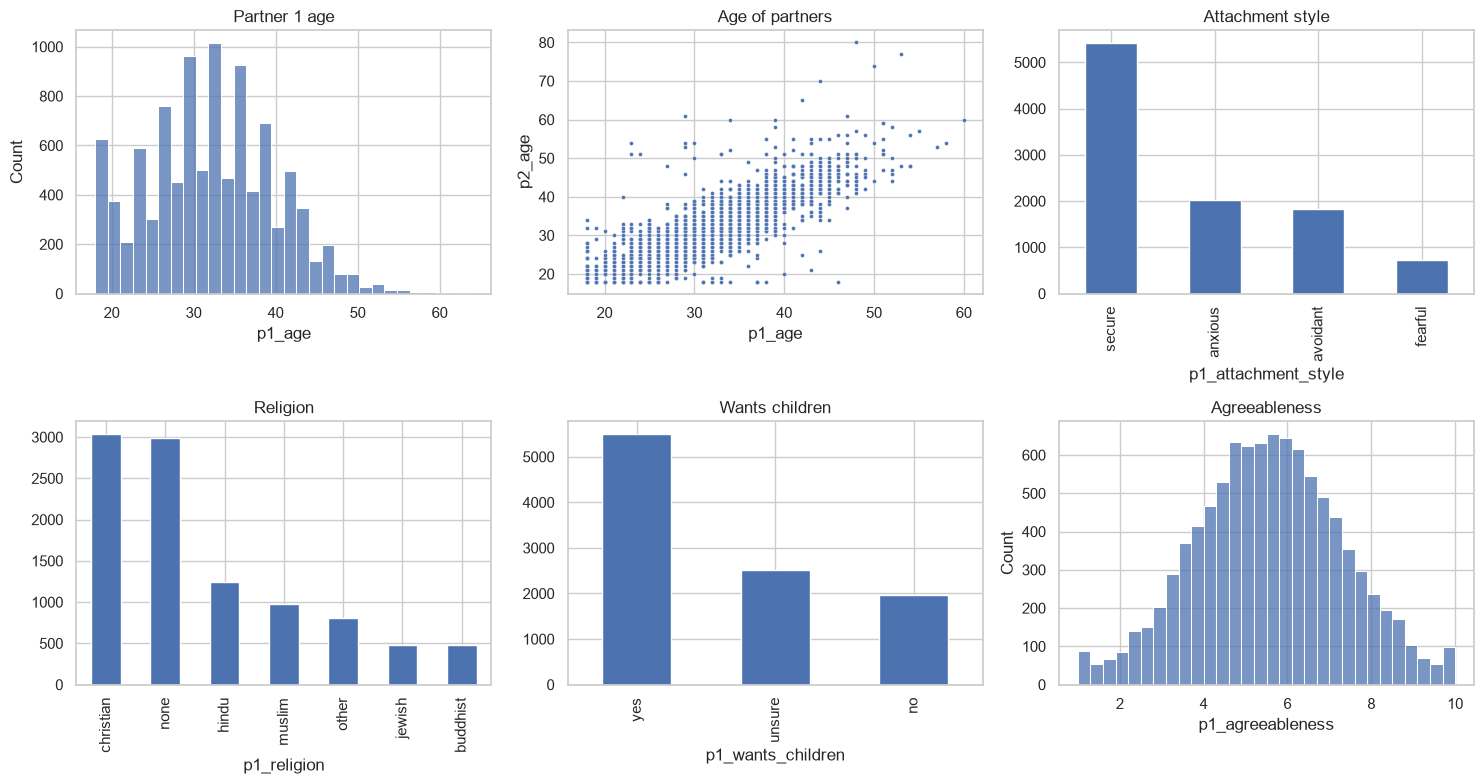

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
sns.histplot(clean['p1_age'], ax=axes[0, 0], bins=30).set(title='Partner 1 age')
sns.scatterplot(x='p1_age', y='p2_age', data=clean.sample(2000, random_state=0), s=8, ax=axes[0, 1]).set(title='Age of partners')
clean['p1_attachment_style'].value_counts().plot.bar(ax=axes[0, 2], title='Attachment style')
clean['p1_religion'].value_counts().plot.bar(ax=axes[1, 0], title='Religion')
clean['p1_wants_children'].value_counts().plot.bar(ax=axes[1, 1], title='Wants children')
sns.histplot(clean['p1_agreeableness'], ax=axes[1, 2], bins=30).set(title='Agreeableness')
plt.tight_layout()

## 5. Engineered pairwise features vs targets

In [8]:
X = build_features(clean)
df = X.join(clean[['compatible', 'longevity_years', 'lasts_5_years']])
X.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age_gap,10000.0,3.62,3.74,0.00,1.00,3.00,5.00,42.00
mean_age,10000.0,32.24,8.02,18.00,26.50,32.00,37.50,65.00
education_diff,10000.0,0.98,0.85,0.00,0.00,1.00,1.00,3.00
mean_education,10000.0,1.08,0.65,0.00,0.50,1.00,1.50,3.00
income_diff,9387.0,1.58,1.21,0.00,1.00,1.00,2.00,4.00
mean_income,9387.0,3.01,1.01,1.00,2.50,3.00,3.50,5.00
religiosity_diff,10000.0,1.60,1.21,0.00,1.00,1.00,2.00,4.00
same_religion,10000.0,0.57,0.49,0.00,0.00,1.00,1.00,1.00
children_match,10000.0,0.70,0.35,0.00,0.50,1.00,1.00,1.00
openness_diff,9379.0,2.04,1.54,0.00,0.80,1.70,3.00,9.00


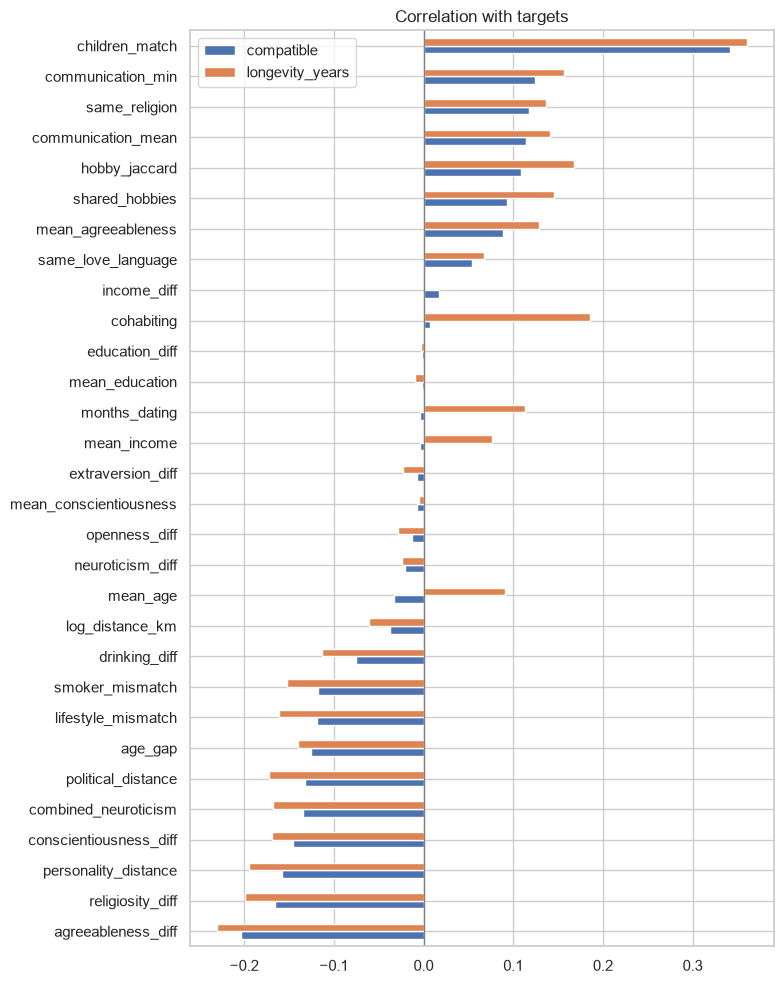

In [9]:
corr = df[NUMERIC_FEATURES + ['compatible', 'longevity_years']].corr()
target_corr = corr[['compatible', 'longevity_years']].drop(['compatible', 'longevity_years'])
target_corr.sort_values('compatible').plot.barh(figsize=(8, 10), title='Correlation with targets')
plt.axvline(0, color='grey', linewidth=1)
plt.tight_layout()

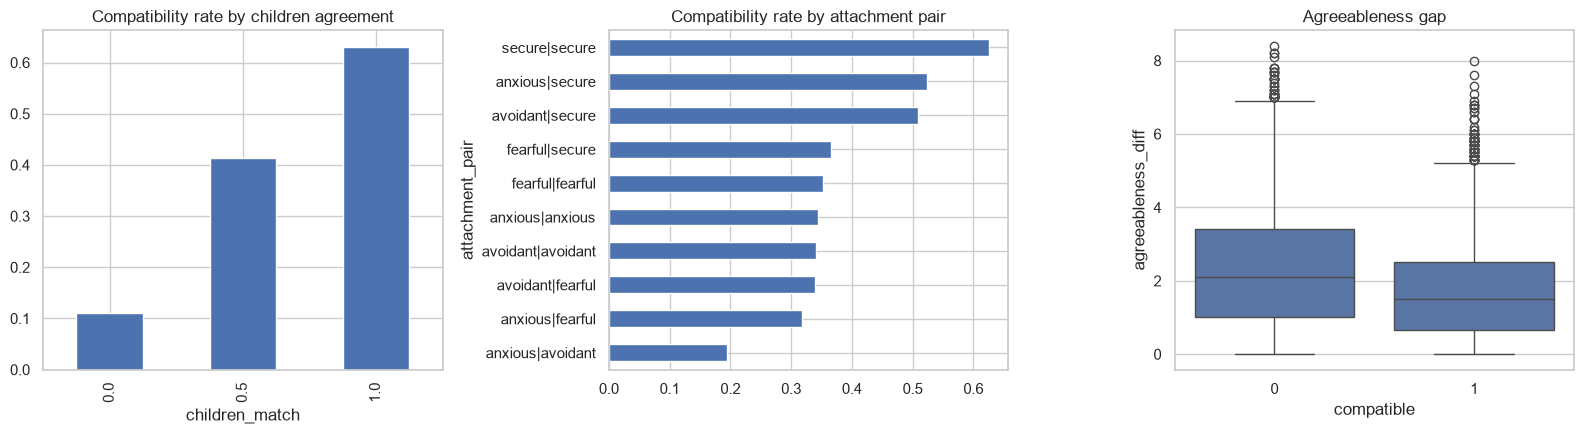

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
df.groupby('children_match')['compatible'].mean().plot.bar(ax=axes[0], title='Compatibility rate by children agreement')
df.groupby('attachment_pair')['compatible'].mean().sort_values().plot.barh(ax=axes[1], title='Compatibility rate by attachment pair')
sns.boxplot(x='compatible', y='agreeableness_diff', data=df, ax=axes[2]).set(title='Agreeableness gap')
plt.tight_layout()

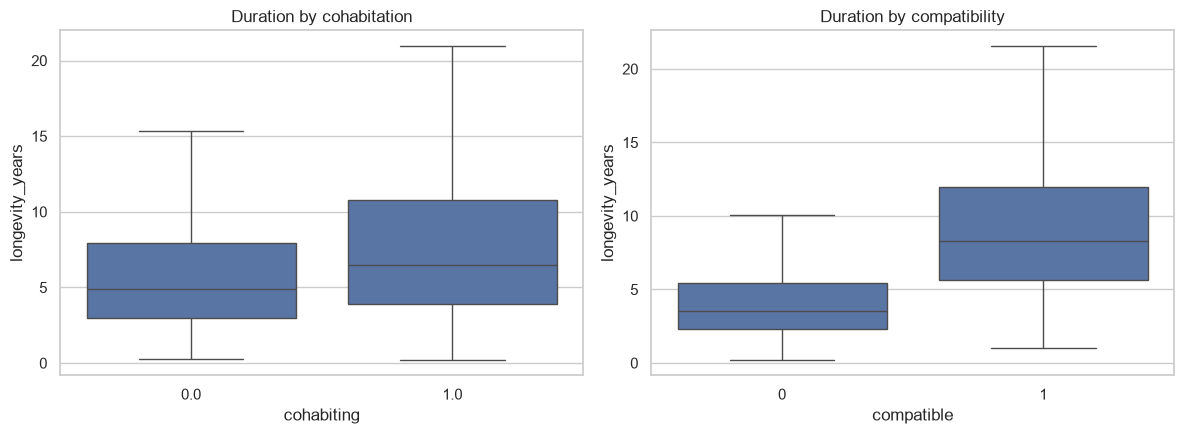

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(x='cohabiting', y='longevity_years', data=df, ax=axes[0], showfliers=False).set(title='Duration by cohabitation')
sns.boxplot(x='compatible', y='longevity_years', data=df, ax=axes[1], showfliers=False).set(title='Duration by compatibility')
plt.tight_layout()

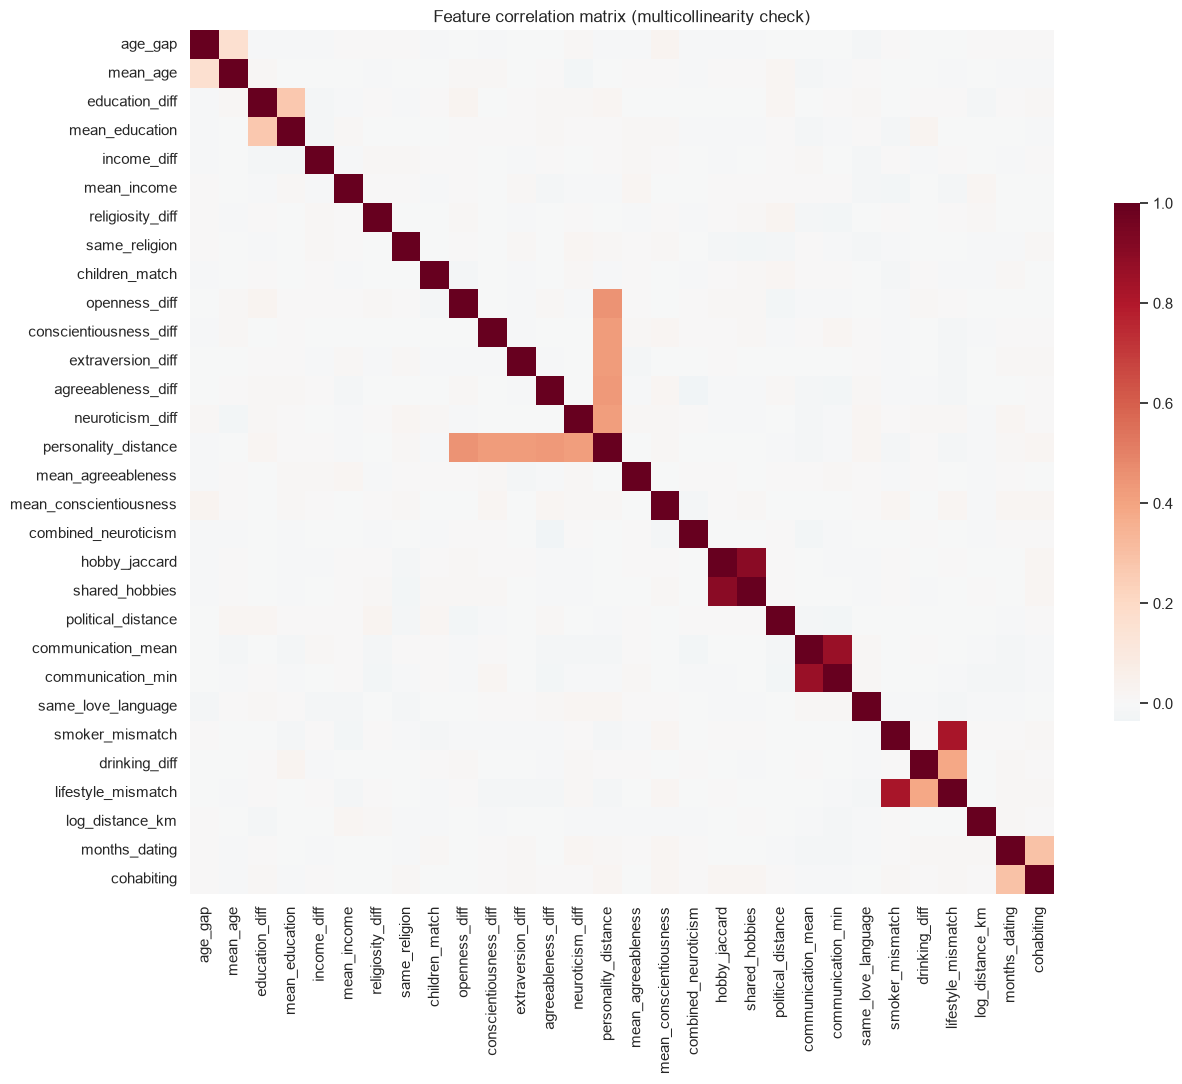

In [12]:
plt.figure(figsize=(14, 11))
sns.heatmap(X[NUMERIC_FEATURES].corr(), cmap='RdBu_r', center=0, square=True, cbar_kws={'shrink': 0.6})
plt.title('Feature correlation matrix (multicollinearity check)')
plt.tight_layout()

## 6. Takeaways
- Classes are balanced (~50% compatible, ~55% last 5+ years), so accuracy and ROC-AUC are meaningful without resampling.
- Duration is strongly right-skewed → regression models are trained on `log1p(years)`.
- Agreement on children, attachment-style pairing, value alignment (religion, politics) and personality gaps are the strongest signals; trait diffs and `personality_distance` are correlated, which favours regularised models.
- Missing values and distance outliers are handled by median imputation and the `log1p` transform inside the model pipeline.